In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from typing import TypedDict 
# from pydantic import BaseModel, Field
import os


In [2]:
api_key = os.getenv("OPENROUTER_API_KEY")

llm = ChatOpenAI(
      model="openrouter/free",
       base_url="https://openrouter.ai" + "/api/v1",
       api_key=api_key,
       temperature=0.2,
       max_tokens=4000,
       max_retries=3,
)

In [3]:
class FindSentimentState(TypedDict):
    text: str
    sentiment: str
    sign: float

In [4]:
def find_sentiment(state: FindSentimentState):

    prompt = f"""
    Analyze sentiment and return only one word:

    positive
    negative
    neutral

    Text:
    {state['text']}
    """

    response = llm.invoke(prompt)

    sentiment = response.content.strip().lower()

    if "positive" in sentiment:
        sign = 1.0
    elif "negative" in sentiment:
        sign = -1.0
    else:
        sign = 0.0

    return {
        "sentiment": sentiment,
        "sign": sign
    }


def neutral_node(state):
    print("Neutral sentiment:", state["text"])
    return {}

def negative_node(state):
    print("Negative sentiment:", state["text"])
    return {}
def positive_node(state):
    print("Positive sentiment:", state["text"])
    return {}

def route_sentiment(state: FindSentimentState):

    if state["sign"] > 0:
        return "positive_node"

    elif state["sign"] < 0:
        return "negative_node"

    return "neutral_node"

In [5]:
graph = StateGraph(FindSentimentState)

graph.add_node("find_sentiment", find_sentiment)
graph.add_node("positive_node", positive_node)
graph.add_node("negative_node", negative_node)
graph.add_node("neutral_node", neutral_node)

graph.add_edge(START, "find_sentiment")


graph.add_edge("positive_node", END)
graph.add_edge("negative_node", END)
graph.add_edge("neutral_node", END)

# graph.add_conditional_edges(
#     "find_sentiment",
#     route_sentiment
# )

graph.add_conditional_edges(
    "find_sentiment",
    route_sentiment,
    
    {
        "positive_node": "positive_node",
        "negative_node": "negative_node",
        "neutral_node": "neutral_node",
    }
)


workflow = graph.compile()

In [6]:
workflow.invoke({
    "text": "This product is fantastic!"
})

Positive sentiment: This product is fantastic!


{'text': 'This product is fantastic!', 'sentiment': 'positive', 'sign': 1.0}

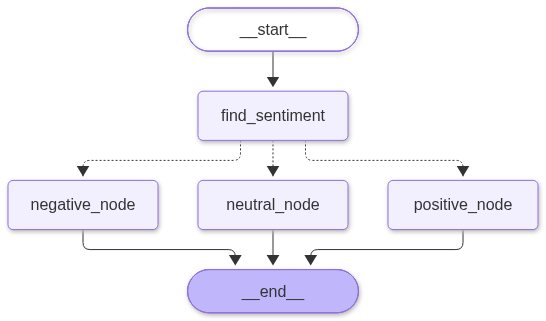

In [7]:
from IPython.display import display, Markdown , Image

Image(workflow.get_graph().draw_mermaid_png())